In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Layer Skipping Strategies

In [2]:
results = pd.read_csv('results/results.csv', index_col=0)
results2 = pd.read_csv('results/results2.csv', index_col=0)
results_deep = pd.read_csv('results/results_deep.csv', index_col=0)
results_deep2 = pd.read_csv('results/results_deep2.csv', index_col=0)
results_1_layer = pd.read_csv('results/results_1_layer.csv', index_col=0)
results_rand = pd.read_csv('results/results_rand.csv', index_col=0)
results_overall_imp = pd.read_csv('results/results_overall_imp.csv', index_col=0)
results_w_rel_L2 = pd.read_csv('results/results_w_rel_L2.csv', index_col=0)

results_threshold = pd.read_csv('results/results_threshold.csv', header=[0, 1], index_col=0)
results_thr_keeping_layers = pd.read_csv('results/results_thr_keeping_layers.csv', index_col=0)
results_threshold_except = pd.read_csv('results/results_threshold_except.csv', header=[0, 1], index_col=0)
results_threshold_rel_except = pd.read_csv('results/results_threshold_rel_except.csv', header=[0, 1], index_col=0)
results_threshold_w_rel_except = pd.read_csv('results/results_threshold_w_rel_except.csv', header=[0, 1], index_col=0)
block_pruner = pd.read_csv('results/results_block_pruner.csv', index_col=0)
block_pruner['del_ratio'] = block_pruner.index / 24

In [3]:
results_rand.loc[:, 'log_perplexity'] = [np.log(x) for x in results_rand.perplexity]
results.loc[:, 'log_perplexity'] = [np.log(x) for x in results.perplexity]
results2.loc[:, 'log_perplexity'] = [np.log(x) for x in results2.perplexity]
results_deep.loc[:, 'log_perplexity'] = [np.log(x) for x in results_deep.perplexity]
results_deep2.loc[:, 'log_perplexity'] = [np.log(x) for x in results_deep2.perplexity]
results_rand.loc[:, 'log_perplexity'] = [np.log(x) for x in results_rand.perplexity]
results_1_layer.loc[:, 'log_perplexity'] = [np.log(x) for x in results_1_layer.perplexity]
results_overall_imp.loc[:, 'log_perplexity'] = [np.log(x) for x in results_overall_imp.perplexity]
results_w_rel_L2.loc[:, 'log_perplexity'] = [np.log(x) for x in results_w_rel_L2.perplexity]
block_pruner.loc[:, 'log_perplexity'] = [np.log(x) for x in block_pruner.perplexity]
# results_threshold_L1.loc[:, 'log_perplexity'] = [np.log(x) for x in results_threshold_L1.perplexity]
# results_threshold_L2.loc[:, 'log_perplexity'] = [np.log(x) for x in results_threshold_L2.perplexity]
# results_threshold_max.loc[:, 'log_perplexity'] = [np.log(x) for x in results_threshold_max.perplexity]

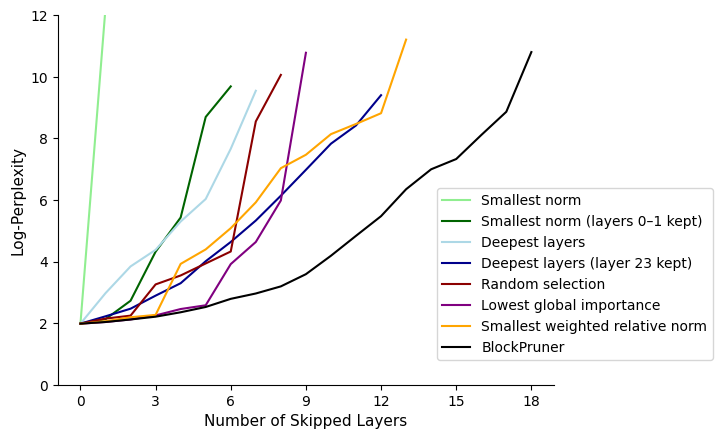

In [4]:
plt.plot(results.log_perplexity, label='Smallest norm', color='lightgreen')
plt.plot(results2.log_perplexity, label='Smallest norm (layers 0–1 kept)', color='darkgreen')
plt.plot(results_deep.log_perplexity, label='Deepest layers', color='lightblue')
plt.plot(results_deep2.log_perplexity, label='Deepest layers (layer 23 kept)', color='darkblue')
# plt.plot(results_shallow.log_perplexity, label='Shallow Layers')
plt.plot(results_rand.log_perplexity, label='Random selection', color='darkred')
plt.plot(results_overall_imp.log_perplexity, label='Lowest global importance', color='purple')
plt.plot(results_w_rel_L2.log_perplexity, label='Smallest weighted relative norm', color='orange')
plt.plot(block_pruner.log_perplexity, c='black', label='BlockPruner')


plt.xlabel('Number of Skipped Layers', fontsize=11)
plt.ylabel('Log-Perplexity', fontsize=11)
plt.ylim((0, 12))
plt.xticks(range(0, 19, 3), range(0, 19, 3))
# plt.xlim((-1, 19))
# plt.legend(loc='lower right')
plt.legend(bbox_to_anchor=(0.75, 0.55))
# plt.title('Layer-Skipping Strategies')
sns.despine()

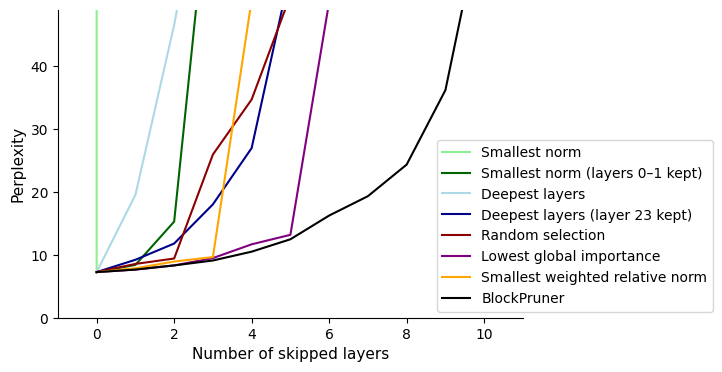

In [20]:
fig, ax = plt.subplots(figsize=(6, 4))

plt.plot(results.perplexity, label='Smallest norm', color='lightgreen')
plt.plot(results2.perplexity, label='Smallest norm (layers 0–1 kept)', color='darkgreen')
plt.plot(results_deep.perplexity, label='Deepest layers', color='lightblue')
plt.plot(results_deep2.perplexity, label='Deepest layers (layer 23 kept)', color='darkblue')
# plt.plot(results_shallow.log_perplexity, label='Shallow Layers')
plt.plot(results_rand.perplexity, label='Random selection', color='darkred')
plt.plot(results_overall_imp.perplexity, label='Lowest global importance', color='purple')
plt.plot(results_w_rel_L2.perplexity, label='Smallest weighted relative norm', color='orange')
plt.plot(block_pruner.perplexity, c='black', label='BlockPruner')

plt.xlabel('Number of skipped layers', fontsize=11)
plt.ylabel('Perplexity', fontsize=11)
plt.ylim((0, 49))
xlim = 11
plt.xticks(range(0, xlim, 2), range(0, xlim, 2))
plt.xlim((-1, xlim))
# plt.legend(loc='lower right')
plt.legend(bbox_to_anchor=(0.80, 0.6))
# plt.title('Layer-Skipping Strategies')
sns.despine()

# Layer Importance

In [21]:
norms_L1 = pd.read_csv('results/large_files/norms_L1.csv', index_col=0)
norms_L2 = pd.read_csv('results/large_files/norms_L2.csv', index_col=0)
norms_max = pd.read_csv('results/large_files/norms_max.csv', index_col=0)

rel_norms_L1 = pd.read_csv('results/large_files/rel_norms_L1.csv', index_col=0)
rel_norms_L2 = pd.read_csv('results/large_files/rel_norms_L2.csv', index_col=0)
rel_norms_max = pd.read_csv('results/large_files/rel_norms_max.csv', index_col=0)

w_rel_norms_L1 = pd.read_csv('results/large_files/w_rel_norms_L1.csv', index_col=0)
w_rel_norms_L2 = pd.read_csv('results/large_files/w_rel_norms_L2.csv', index_col=0)
w_rel_norms_max = pd.read_csv('results/large_files/w_rel_norms_max.csv', index_col=0)

results_1_layer = pd.read_csv('results/results_1_layer.csv', index_col=0)
block_pruner = pd.read_csv('results/block_pruner_importance.csv', index_col=0)

In [101]:
dfs = {
    'L1 norm': norms_L1,
    'L2 norm': norms_L2,
    'Max norm': norms_max,
    'Relative L1 norm': rel_norms_L1,
    'Relative L2 norm': rel_norms_L2,
    'Relative Max norm': rel_norms_max,
    'Weighted relative L1 norm': w_rel_norms_L1,
    'Weighted relative L2 norm': w_rel_norms_L2,
    'Weighted relative Max norm': w_rel_norms_max,
}

importances = results_1_layer[['perplexity']].rename(columns={'perplexity':'Global importance'}).join([
        df.mean().reset_index(drop=True).rename(name)
        for name, df in dfs.items()
])

In [36]:
layer_importances = block_pruner.rename(
    columns={'importance': 'BlockPruner importance'}
).join(importances)
layer_importances.to_csv('results/layer_importance.csv', index=False)

In [37]:
df = np.log(importances.iloc[:, [2, 5, 8, 0]])
df_norm = (df - df.min()) / (df.max() - df.min())

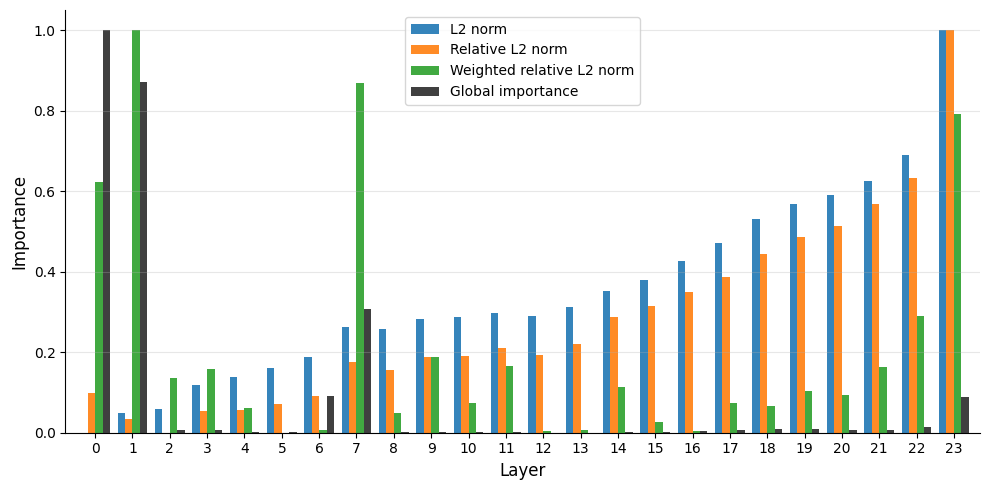

In [46]:
df = df_norm

x = np.arange(len(df))          # group positions (rows)
n_cols = df.shape[1]
width = 0.8 / n_cols            # bar width per group

fig, ax = plt.subplots(figsize=(10, 5))

for i, col in enumerate(df.columns):
    if i < 3:
        ax.bar(x + i * width, df[col].values,
            width=width, label=col, alpha=0.9)
    else:
        ax.bar(x + i * width, df[col].values,
            width=width, label=col, alpha=0.75, color='black')
ax.set_xlabel('Layer', fontsize=12)
ax.set_ylabel('Importance', fontsize=12)

ax.set_xticks(x + width * (n_cols - 1) / 2)
ax.set_xticklabels(df.index)#, rotation=45, ha='right')
ax.set_xlim((-0.5, 24))
ax.legend()
ax.grid(axis='y', alpha=0.3)

sns.despine()
plt.tight_layout()
plt.show()

# Router results

In [54]:
all_results = pd.read_csv('results/prediction_results.csv', index_col=0)

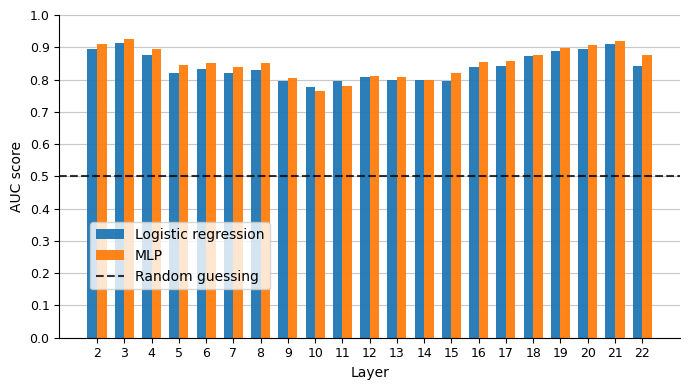

In [55]:
layers = list(all_results.index)
x = np.arange(len(layers))  # positions for the bars
width = 0.35  # width of the bars

plt.figure(figsize=(7, 4))

# Bar plots for logistic regression and MLP
bar1 = plt.bar(x - width/2, all_results['AUC'], width, alpha=0.95)
bar2 = plt.bar(x + width/2, all_results['AUC_mlp'], width, alpha=0.95)
# Horizontal line for random guessing
line = plt.axhline(0.5, linestyle='--', color='black', alpha=0.8)

plt.legend([bar1, bar2, line],
           ['Logistic regression', 'MLP', 'Random guessing'],
           loc=(0.05, 0.15))

# plt.title('Best AUC score per Layer')
plt.xlabel('Layer')
plt.ylabel('AUC score')
plt.ylim(0, 1)
plt.xticks(x, layers, fontsize=9)
plt.yticks([i/10 for i in range(11)], fontsize=9)
# plt.legend(loc=(0.05, 0.15))
plt.grid(axis='y', linestyle='-', alpha=0.7)

ax = plt.gca()
ax.set_axisbelow(True)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

plt.tight_layout()
plt.show()

In [56]:
norms_L1 = pd.read_csv('results/large_files/norms_L1.csv', index_col=0)
norms_L2 = pd.read_csv('results/large_files/norms_L2.csv', index_col=0)
norms_max = pd.read_csv('results/large_files/norms_max.csv', index_col=0)

rel_norms_L1 = pd.read_csv('results/large_files/rel_norms_L1.csv', index_col=0)
rel_norms_L2 = pd.read_csv('results/large_files/rel_norms_L2.csv', index_col=0)
rel_norms_max = pd.read_csv('results/large_files/rel_norms_max.csv', index_col=0)

w_rel_norms_L1 = pd.read_csv('results/large_files/w_rel_norms_L1.csv', index_col=0)
w_rel_norms_L2 = pd.read_csv('results/large_files/w_rel_norms_L2.csv', index_col=0)
w_rel_norms_max = pd.read_csv('results/large_files/w_rel_norms_max.csv', index_col=0)

In [57]:
pd.DataFrame({
    'L1': norms_L1.mean(), 'L2': norms_L2.mean(), 'max': norms_max.mean(),
    'rel_L1': rel_norms_L1.mean(), 'rel_L2': rel_norms_L2.mean(), 'rel_max': rel_norms_max.mean(),
    'w_rel_L1': 100*w_rel_norms_L1.mean(), 'w_rel_L2': 100*w_rel_norms_L2.mean(), 'w_rel_max': 100*w_rel_norms_max.mean()
})

,L1,L2,max,rel_L1,rel_L2,rel_max,w_rel_L1,w_rel_L2,w_rel_max
0,412.533127,14.517113,4.469790,8.355881,11.126073,16.511554,0.087024,1.102550,4.370723
1,496.691944,18.388416,7.204328,7.671639,9.272638,10.789579,1.139931,15.681302,23.519323
2,679.819115,19.324569,2.763289,8.538233,8.421093,7.433968,0.014138,0.036371,0.143030
3,904.641558,25.971058,4.323604,9.987702,9.823297,8.404168,0.015141,0.042725,0.137890
4,998.149976,28.535166,4.840937,9.931682,9.829225,9.509250,0.009925,0.021582,0.068743
5,1123.028738,31.641284,4.509568,10.473000,10.246061,9.149375,0.007681,0.013984,0.041972
6,1275.780357,36.316221,6.553882,11.247187,10.831383,10.372708,0.007218,0.014719,0.040487
7,1459.292892,52.295473,23.943427,12.264565,13.745129,20.516824,0.321659,6.214754,12.734069
8,1761.262764,50.885283,10.507699,13.464531,12.994005,10.101384,0.006922,0.019868,0.048596
9,1873.508682,57.390542,18.661073,14.116569,14.217176,15.308393,0.009722,0.052780,0.129114


In [58]:
block_pruner = pd.read_csv('results/results_block_pruner.csv', index_col=0)
block_pruner['del_ratio'] = block_pruner.index / 24
wrell2 = pd.read_csv('results/results_w_rel_L2.csv', index_col=0)
wrell2['del_ratio'] = wrell2.index / 24

small_changes = pd.read_csv('results/results_threshold_rel_except.csv', index_col=0, header=[0, 1])
small_changes = small_changes.loc[:, [('perplexity', 'L1'), ('ratio_del', 'L1')]]

results = {}
results['r'] = pd.read_csv('results/results_router.csv', index_col=0)
results['topk'] = pd.read_csv('results/results_router_topk.csv', index_col=[0, 1])
results['thr'] = pd.read_csv('results/results_router_thr.csv', index_col=0)
results['singleskip'] = pd.read_csv('results/results_singleskip_router.csv', index_col=0)
results['singleskip_topk'] = pd.read_csv('results/results_router_singleskip_topk.csv', index_col=[0, 1])
results['singleskip_rnd'] = pd.read_csv('results/results_rnd_singleskip_router.csv', index_col=0)

results_v2 = {}
results_v2['r'] = pd.read_csv('results/results_router_v2.csv', index_col=0)
results_v2['thr'] = pd.read_csv('results/results_router_thr_v2.csv', index_col=0)
results_v2['singleskip'] = pd.read_csv('results/results_singleskip_router_v2.csv', index_col=0)
results_v2['singleskip_topk'] = pd.read_csv('results/results_router_singleskip_topk_v2.csv', index_col=[0, 1])
results_v2['singleskip_rnd'] = pd.read_csv('results/results_rnd_singleskip_router_v2.csv', index_col=0)

results_v3 = {}
results_v3['singleskip'] = pd.read_csv('results/results_singleskip_router_v3ss.csv', index_col=0)
results_v3['singleskip_topk'] = pd.read_csv('results/results_router_singleskip_topk_v3ss.csv', index_col=[0, 1])

In [59]:
small_changes

,perplexity,ratio_del
norm_type,L1,L1
threshold,,
10.0,7.972623,0.084726
15.0,9.273826,0.147849
20.0,12.126037,0.217589
25.0,18.576084,0.294627
30.0,32.519547,0.369392
35.0,59.711651,0.435732
40.0,109.271408,0.493702
45.0,188.167282,0.540290


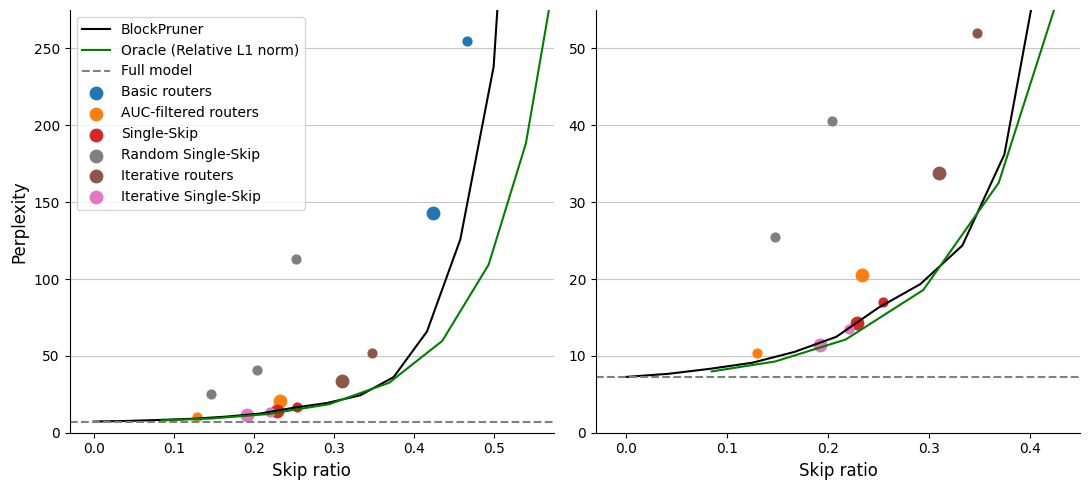

In [103]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=False)

# ---------- LEFT SUBPLOT ----------
ax = axes[0]

ax.plot(block_pruner.loc[:13, 'del_ratio'], block_pruner.loc[:13, 'perplexity'], 
        c='black', label='BlockPruner')
ax.plot(small_changes.loc[:, 'ratio_del'], small_changes.loc[:, 'perplexity'], 
        c='g', label='Oracle (Relative L1 norm)')

ax.axhline(block_pruner.loc[0, 'perplexity'], c='gray', linestyle='--', label='Full model')

ax.scatter(results['r'].loc['lr', 'del_ratio'], results['r'].loc['lr', 'perplexity'], 
           s=40, c='tab:blue')
ax.scatter(results['r'].loc['nn', 'del_ratio'], results['r'].loc['nn', 'perplexity'], 
           s=80, c='tab:blue', label='Basic routers')

ax.scatter(results['thr'].loc['lr', 'del_ratio'], results['thr'].loc['lr', 'perplexity'], 
           s=40, c='tab:orange')
ax.scatter(results['thr'].loc['nn', 'del_ratio'], results['thr'].loc['nn', 'perplexity'], 
           s=80, c='tab:orange', label='AUC-filtered routers')

ax.scatter(results['singleskip'].loc['lr', 'del_ratio'], results['singleskip'].loc['lr', 'perplexity'], 
           s=40, c='tab:red')
ax.scatter(results['singleskip'].loc['nn', 'del_ratio'], results['singleskip'].loc['nn', 'perplexity'], 
           s=80, c='tab:red', label='Single-Skip')

ax.scatter(results['singleskip_rnd'].loc[:, 'del_ratio'], results['singleskip_rnd'].loc[:, 'perplexity'], 
           s=40, c='tab:gray')
ax.scatter([], [], s=80, c='tab:gray', label='Random Single-Skip')

ax.scatter(results_v2['r'].loc['lr', 'del_ratio'], results_v2['r'].loc['lr', 'perplexity'], 
           s=40, c='tab:brown')
ax.scatter(results_v2['r'].loc['nn', 'del_ratio'], results_v2['r'].loc['nn', 'perplexity'], 
           s=80, c='tab:brown', label='Iterative routers')

ax.scatter(results_v3['singleskip'].loc['lr', 'del_ratio'], results_v3['singleskip'].loc['lr', 'perplexity'], 
           s=40, c='tab:pink')
ax.scatter(results_v3['singleskip'].loc['nn', 'del_ratio'], results_v3['singleskip'].loc['nn', 'perplexity'], 
           s=80, c='tab:pink', label='Iterative Single-Skip')

ax.set_xlim((-0.03, 0.575))
ax.set_ylim((0, 275))
ax.set_xlabel('Skip ratio', fontsize=12)
ax.set_ylabel('Perplexity', fontsize=12)

ax.grid(axis='y', linestyle='-', alpha=0.7)
ax.set_axisbelow(True)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

ax.legend()

# ---------- RIGHT SUBPLOT ----------
ax = axes[1]

ax.plot(block_pruner.loc[:13, 'del_ratio'], block_pruner.loc[:13, 'perplexity'], 
        c='black', label='BlockPruner')

ax.plot(small_changes.loc[:, 'ratio_del'], small_changes.loc[:, 'perplexity'], 
        c='g', label='Oracle (relative L1 norm)')

ax.axhline(block_pruner.loc[0, 'perplexity'], c='gray', linestyle='--', label='full model')

ax.scatter(results['r'].loc['lr', 'del_ratio'], results['r'].loc['lr', 'perplexity'],
           s=40, c='tab:blue')
ax.scatter(results['r'].loc['nn', 'del_ratio'], results['r'].loc['nn', 'perplexity'],
           s=80, c='tab:blue', label='Basic routers')

ax.scatter(results['thr'].loc['lr', 'del_ratio'], results['thr'].loc['lr', 'perplexity'],
           s=40, c='tab:orange')
ax.scatter(results['thr'].loc['nn', 'del_ratio'], results['thr'].loc['nn', 'perplexity'],
           s=80, c='tab:orange', label='AUC-filtered routers')

ax.scatter(results['singleskip'].loc['lr', 'del_ratio'], results['singleskip'].loc['lr', 'perplexity'],
           s=40, c='tab:red')
ax.scatter(results['singleskip'].loc['nn', 'del_ratio'], results['singleskip'].loc['nn', 'perplexity'],
           s=80, c='tab:red', label='Single-Skip')

ax.scatter(results['singleskip_rnd'].loc[:, 'del_ratio'], results['singleskip_rnd'].loc[:, 'perplexity'],
           s=40, c='tab:gray')
ax.scatter([], [], s=80, c='tab:gray', label='Random Single-Skip')

ax.scatter(results_v2['r'].loc['lr', 'del_ratio'], results_v2['r'].loc['lr', 'perplexity'],
           s=40, c='tab:brown')
ax.scatter(results_v2['r'].loc['nn', 'del_ratio'], results_v2['r'].loc['nn', 'perplexity'],
           s=80, c='tab:brown', label='Iterative routers')

ax.scatter(results_v3['singleskip'].loc['lr', 'del_ratio'], results_v3['singleskip'].loc['lr', 'perplexity'],
           s=40, c='tab:pink')
ax.scatter(results_v3['singleskip'].loc['nn', 'del_ratio'], results_v3['singleskip'].loc['nn', 'perplexity'],
           s=80, c='tab:pink', label='Iterative Single-Skip')

ax.set_xlim((-0.03, 0.45))
ax.set_ylim((0, 55))
ax.set_xlabel('Skip ratio', fontsize=12)
# ax.set_ylabel('Perplexity')

ax.grid(axis='y', linestyle='-', alpha=0.7)
ax.set_axisbelow(True)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

plt.tight_layout()

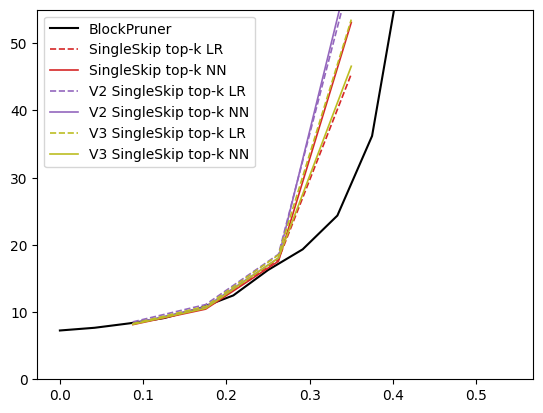

In [8]:
###
plt.plot(block_pruner.loc[:13, 'del_ratio'], block_pruner.loc[:13, 'perplexity'], c='black', label='BlockPruner')

ss_topk_lr = results['singleskip_topk'].query('router_type == "lr"')
plt.plot(ss_topk_lr.del_ratio, ss_topk_lr.perplexity, c='tab:red', ls='--', lw=1.2, label='SingleSkip top-k LR')
ss_topk_nn = results['singleskip_topk'].query('router_type == "nn"')
plt.plot(ss_topk_nn.del_ratio, ss_topk_nn.perplexity, c='tab:red', lw=1.2, label='SingleSkip top-k NN')

ss_topk_lr = results_v2['singleskip_topk'].query('router_type == "lr"')
plt.plot(ss_topk_lr.del_ratio, ss_topk_lr.perplexity, c='tab:purple', ls='--', lw=1.2, label='V2 SingleSkip top-k LR')
ss_topk_nn = results_v2['singleskip_topk'].query('router_type == "nn"')
plt.plot(ss_topk_nn.del_ratio, ss_topk_nn.perplexity, c='tab:purple', lw=1.2, label='V2 SingleSkip top-k NN')

ss_topk_lr = results_v3['singleskip_topk'].query('router_type == "lr"')
plt.plot(ss_topk_lr.del_ratio, ss_topk_lr.perplexity, c='tab:olive', ls='--', lw=1.2, label='V3 SingleSkip top-k LR')
ss_topk_nn = results_v3['singleskip_topk'].query('router_type == "nn"')
plt.plot(ss_topk_nn.del_ratio, ss_topk_nn.perplexity, c='tab:olive', lw=1.2, label='V3 SingleSkip top-k NN')

plt.ylim((0, 55))
plt.legend();

# Gate Results

In [65]:
gate_results = pd.read_csv('results/gate_training.csv', index_col=0)

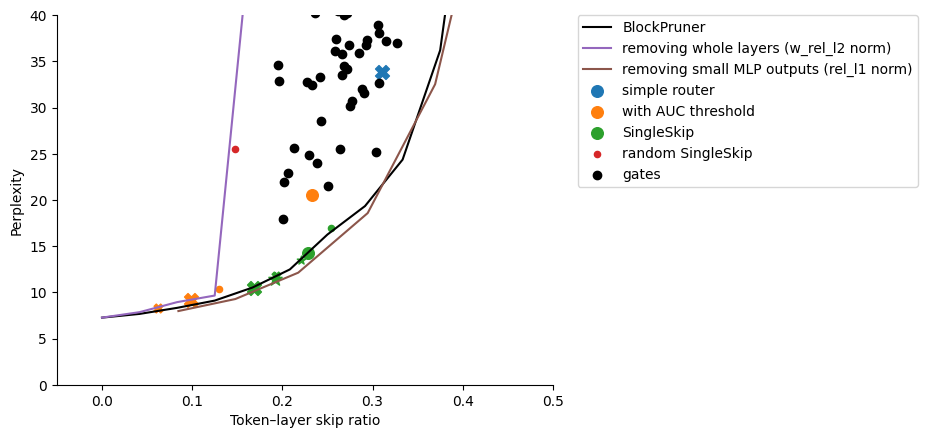

In [67]:
# plt.plot(block_pruner.del_ratio, block_pruner.perplexity)
plt.plot(block_pruner.loc[:13, 'del_ratio'], block_pruner.loc[:13, 'perplexity'], c='black', label='BlockPruner')
plt.plot(wrell2.loc[:13, 'del_ratio'], wrell2.loc[:13, 'perplexity'], c='tab:purple', label='removing whole layers (w_rel_l2 norm)')
plt.plot(small_changes.loc[:, 'ratio_del'], small_changes.loc[:, 'perplexity'], c='tab:brown', label='removing small MLP outputs (rel_l1 norm)')

plt.scatter(results['r'].loc['lr', 'del_ratio'], results['r'].loc['lr', 'perplexity'], marker='o', s=20, c='tab:blue') #, label='LR router')
plt.scatter(results['r'].loc['nn', 'del_ratio'], results['r'].loc['nn', 'perplexity'], marker='o', s=70, c='tab:blue', label='simple router') #, label='NN router')
plt.scatter(results_v2['r'].loc['lr', 'del_ratio'], results_v2['r'].loc['lr', 'perplexity'], marker='X', s=40, c='tab:blue')
plt.scatter(results_v2['r'].loc['nn', 'del_ratio'], results_v2['r'].loc['nn', 'perplexity'], marker='X', s=100, c='tab:blue') #, label='iteratively trained')

###

plt.scatter(results['thr'].loc['lr', 'del_ratio'], results['thr'].loc['lr', 'perplexity'], marker='o', s=20, c='tab:orange')
plt.scatter(results['thr'].loc['nn', 'del_ratio'], results['thr'].loc['nn', 'perplexity'], marker='o', s=70, c='tab:orange', label='with AUC threshold')
plt.scatter(results_v2['thr'].loc['lr', 'del_ratio'], results_v2['thr'].loc['lr', 'perplexity'], marker='X', s=40, c='tab:orange')
plt.scatter(results_v2['thr'].loc['nn', 'del_ratio'], results_v2['thr'].loc['nn', 'perplexity'], marker='X', s=100, c='tab:orange')

###

plt.scatter(results['singleskip'].loc['lr', 'del_ratio'], results['singleskip'].loc['lr', 'perplexity'], marker='o', s=20, c='tab:green')
plt.scatter(results['singleskip'].loc['nn', 'del_ratio'], results['singleskip'].loc['nn', 'perplexity'], marker='o', s=70, c='tab:green', label='SingleSkip')
plt.scatter(results_v2['singleskip'].loc['lr', 'del_ratio'], results_v2['singleskip'].loc['lr', 'perplexity'], marker='X', s=40, c='tab:green')
plt.scatter(results_v2['singleskip'].loc['nn', 'del_ratio'], results_v2['singleskip'].loc['nn', 'perplexity'], marker='X', s=100, c='tab:green')
plt.scatter(results_v3['singleskip'].loc['lr', 'del_ratio'], results_v3['singleskip'].loc['lr', 'perplexity'], marker='*', s=40, c='tab:green')
plt.scatter(results_v3['singleskip'].loc['nn', 'del_ratio'], results_v3['singleskip'].loc['nn', 'perplexity'], marker='*', s=100, c='tab:green')

###

plt.scatter(results['singleskip_rnd'].loc[:, 'del_ratio'], results['singleskip_rnd'].loc[:, 'perplexity'], marker='o', s=20, c='tab:red', label='random SingleSkip')

###

plt.scatter(gate_results.skip_ratio, gate_results.val_ppl, c='black', label='gates')

###

plt.xlim((-0.05, 0.5))
plt.ylim((0, 40))

plt.xlabel('Token–layer skip ratio')
plt.ylabel('Perplexity')

# plt.legend();
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
sns.despine();

In [70]:
gate_results.sort_values(by="val_ppl").head(10)

,target_skip,grad_accum_steps,run_i,val_ppl,skip_ratio,n_samples
lr,,,,,,
0.005,0.30,4.0,0.0,17.959000,0.200867,256.0
0.007,0.30,1.0,1.0,21.534990,0.250982,128.0
0.007,0.30,4.0,2.0,21.948141,0.201940,128.0
0.005,0.30,4.0,2.0,22.943251,0.206680,256.0
0.010,0.30,1.0,2.0,23.993603,0.238632,128.0
0.010,0.35,4.0,2.0,24.839018,0.229101,128.0
0.005,0.35,4.0,0.0,25.230175,0.303828,256.0
0.007,0.30,4.0,0.0,25.508720,0.263870,512.0
0.007,0.30,4.0,1.0,25.573433,0.213099,256.0


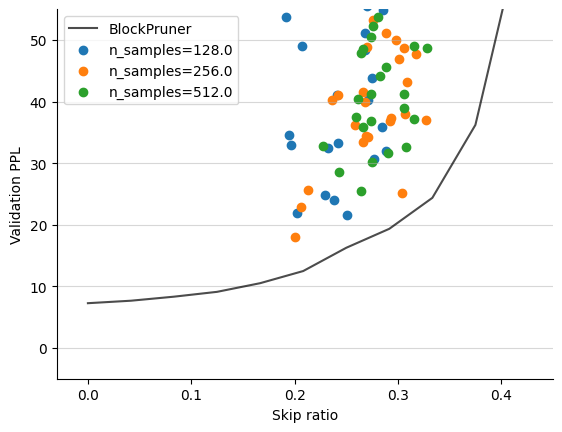

In [71]:
# results_df = gate_results.query('n_samples==256')
results_df = gate_results
param = "n_samples"  # 4
# param = "grad_accum_steps"  # 4
# param = "lr" # 0.005
# param = "target_skip"
plt.plot(block_pruner.loc[:13, 'del_ratio'], block_pruner.loc[:13, 'perplexity'], c='black', alpha=0.7, label='BlockPruner')
for x, group in results_df.groupby(param):
    plt.scatter(group["skip_ratio"], group["val_ppl"],
                label=f"{param}={x}")
plt.xlim((-0.03, 0.45))
plt.ylim((-5, 55))
plt.grid(axis='y', alpha=0.5)
plt.xlabel("Skip ratio")
plt.ylabel("Validation PPL")
plt.legend(title=param)
plt.legend(loc="upper left")
sns.despine()
plt.show()

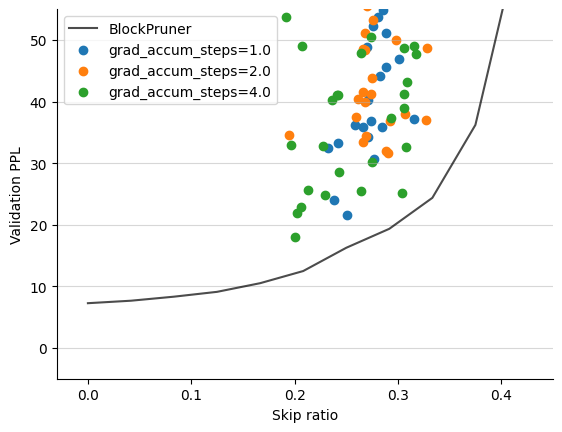

In [72]:
# results_df = gate_results.query('n_samples==256')
results_df = gate_results
# param = "n_samples"  # 4
param = "grad_accum_steps"  # 4
# param = "lr" # 0.005
# param = "target_skip"
plt.plot(block_pruner.loc[:13, 'del_ratio'], block_pruner.loc[:13, 'perplexity'], c='black', alpha=0.7, label='BlockPruner')
for x, group in results_df.groupby(param):
    plt.scatter(group["skip_ratio"], group["val_ppl"],
                label=f"{param}={x}")
plt.xlim((-0.03, 0.45))
plt.ylim((-5, 55))
plt.grid(axis='y', alpha=0.5)
plt.xlabel("Skip ratio")
plt.ylabel("Validation PPL")
plt.legend(title=param)
plt.legend(loc="upper left")
sns.despine()
plt.show()

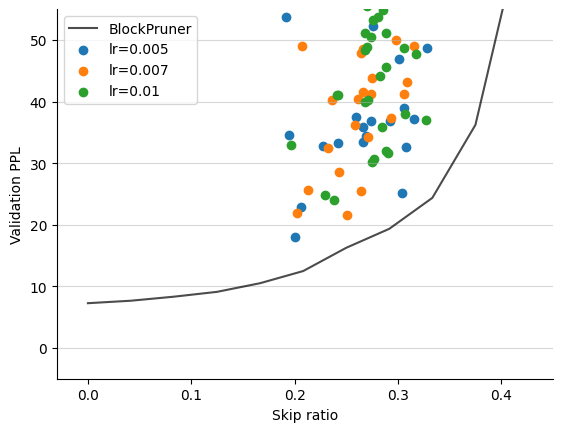

In [73]:
# results_df = gate_results.query('n_samples==256')
results_df = gate_results
# param = "n_samples"  # 4
# param = "grad_accum_steps"  # 4
param = "lr" # 0.005
# param = "target_skip"
plt.plot(block_pruner.loc[:13, 'del_ratio'], block_pruner.loc[:13, 'perplexity'], c='black', alpha=0.7, label='BlockPruner')
for x, group in results_df.groupby(param):
    plt.scatter(group["skip_ratio"], group["val_ppl"],
                label=f"{param}={x}")
plt.xlim((-0.03, 0.45))
plt.ylim((-5, 55))
plt.grid(axis='y', alpha=0.5)
plt.xlabel("Skip ratio")
plt.ylabel("Validation PPL")
plt.legend(title=param)
plt.legend(loc="upper left")
sns.despine()
plt.show()

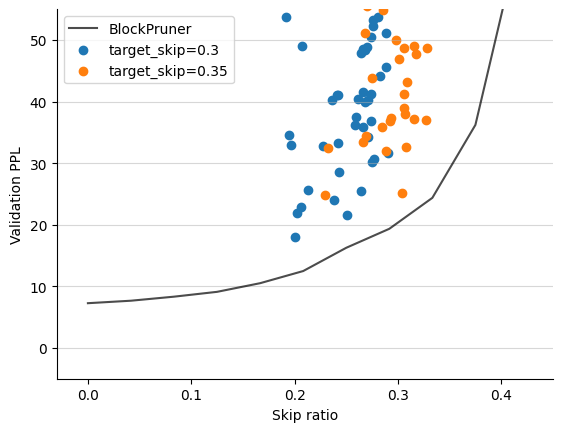

In [74]:
# results_df = gate_results.query('n_samples==256')
results_df = gate_results
# param = "n_samples"  # 4
# param = "grad_accum_steps"  # 4
# param = "lr" # 0.005
param = "target_skip"
plt.plot(block_pruner.loc[:13, 'del_ratio'], block_pruner.loc[:13, 'perplexity'], c='black', alpha=0.7, label='BlockPruner')
for x, group in results_df.groupby(param):
    plt.scatter(group["skip_ratio"], group["val_ppl"],
                label=f"{param}={x}")
plt.xlim((-0.03, 0.45))
plt.ylim((-5, 55))
plt.grid(axis='y', alpha=0.5)
plt.xlabel("Skip ratio")
plt.ylabel("Validation PPL")
plt.legend(title=param)
plt.legend(loc="upper left")
sns.despine()
plt.show()

# New gate results (KLdiv, separate param groups)

In [75]:
gate_results = pd.concat([
    pd.read_csv('results/kl_gate_training_128.csv'), 
    pd.read_csv('results/kl_gate_training_256.csv'), 
    pd.read_csv('results/kl_gate_training_512.csv')
])
gate_results.to_csv('results/kl_gate_training.csv', index=False)

In [76]:
gate_results.loc[(gate_results['skip_ratio'] > 0.25) & (gate_results['val_ppl'] < 60)].sort_values(by='val_ppl')

,n_samples,lrb,lrw,run_i,val_ppl,skip_ratio,init_skip,target_skip
24,512.0,1.0,1.000000e-02,0.0,10.662846,0.252162,0.3,0.3
78,512.0,1.0,1.000000e-02,1.0,10.899587,0.256897,0.5,0.3
26,512.0,1.0,1.000000e-02,2.0,10.913402,0.251714,0.3,0.3
25,512.0,1.0,1.000000e-02,1.0,11.036218,0.256231,0.3,0.3
85,512.0,0.1,1.000000e-02,0.0,11.085263,0.255686,0.5,0.3
...,...,...,...,...,...,...,...,...
123,512.0,0.1,1.000000e-03,0.0,55.200920,0.437129,0.5,0.5
18,128.0,10.0,1.000000e-08,0.0,55.575165,0.291743,0.3,0.3
30,256.0,10.0,1.000000e-04,0.0,55.692631,0.345398,0.3,0.4
140,128.0,1.0,1.000000e-02,1.0,57.752445,0.447881,0.3,0.5


In [77]:
# results_df = gate_results.loc[(gate_results['skip_ratio'] > 0.25) & (gate_results['val_ppl'] < 60) & (gate_results['n_samples'] == 128)].sort_values(by='val_ppl')
results_df = gate_results

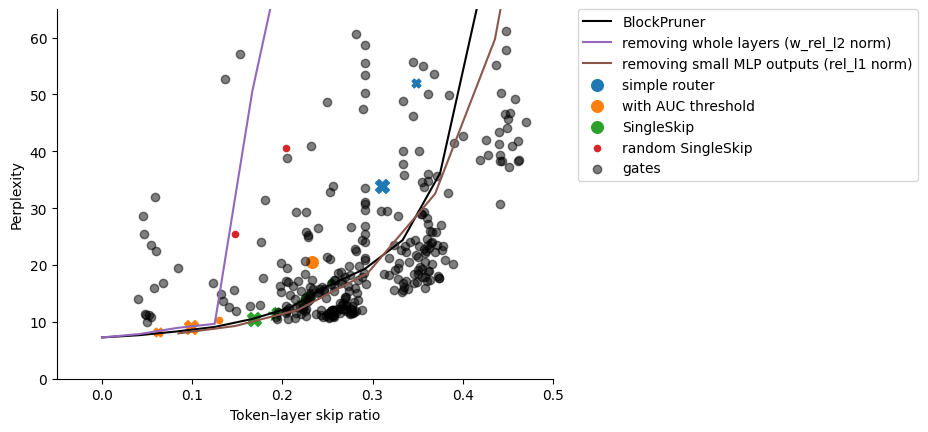

In [78]:
# plt.plot(block_pruner.del_ratio, block_pruner.perplexity)
plt.plot(block_pruner.loc[:13, 'del_ratio'], block_pruner.loc[:13, 'perplexity'], c='black', label='BlockPruner')
plt.plot(wrell2.loc[:13, 'del_ratio'], wrell2.loc[:13, 'perplexity'], c='tab:purple', label='removing whole layers (w_rel_l2 norm)')
plt.plot(small_changes.loc[:, 'ratio_del'], small_changes.loc[:, 'perplexity'], c='tab:brown', label='removing small MLP outputs (rel_l1 norm)')

plt.scatter(results['r'].loc['lr', 'del_ratio'], results['r'].loc['lr', 'perplexity'], marker='o', s=20, c='tab:blue') #, label='LR router')
plt.scatter(results['r'].loc['nn', 'del_ratio'], results['r'].loc['nn', 'perplexity'], marker='o', s=70, c='tab:blue', label='simple router') #, label='NN router')
plt.scatter(results_v2['r'].loc['lr', 'del_ratio'], results_v2['r'].loc['lr', 'perplexity'], marker='X', s=40, c='tab:blue')
plt.scatter(results_v2['r'].loc['nn', 'del_ratio'], results_v2['r'].loc['nn', 'perplexity'], marker='X', s=100, c='tab:blue') #, label='iteratively trained')

###

plt.scatter(results['thr'].loc['lr', 'del_ratio'], results['thr'].loc['lr', 'perplexity'], marker='o', s=20, c='tab:orange')
plt.scatter(results['thr'].loc['nn', 'del_ratio'], results['thr'].loc['nn', 'perplexity'], marker='o', s=70, c='tab:orange', label='with AUC threshold')
plt.scatter(results_v2['thr'].loc['lr', 'del_ratio'], results_v2['thr'].loc['lr', 'perplexity'], marker='X', s=40, c='tab:orange')
plt.scatter(results_v2['thr'].loc['nn', 'del_ratio'], results_v2['thr'].loc['nn', 'perplexity'], marker='X', s=100, c='tab:orange')

###

plt.scatter(results['singleskip'].loc['lr', 'del_ratio'], results['singleskip'].loc['lr', 'perplexity'], marker='o', s=20, c='tab:green')
plt.scatter(results['singleskip'].loc['nn', 'del_ratio'], results['singleskip'].loc['nn', 'perplexity'], marker='o', s=70, c='tab:green', label='SingleSkip')
plt.scatter(results_v2['singleskip'].loc['lr', 'del_ratio'], results_v2['singleskip'].loc['lr', 'perplexity'], marker='X', s=40, c='tab:green')
plt.scatter(results_v2['singleskip'].loc['nn', 'del_ratio'], results_v2['singleskip'].loc['nn', 'perplexity'], marker='X', s=100, c='tab:green')
plt.scatter(results_v3['singleskip'].loc['lr', 'del_ratio'], results_v3['singleskip'].loc['lr', 'perplexity'], marker='*', s=40, c='tab:green')
plt.scatter(results_v3['singleskip'].loc['nn', 'del_ratio'], results_v3['singleskip'].loc['nn', 'perplexity'], marker='*', s=100, c='tab:green')

###

plt.scatter(results['singleskip_rnd'].loc[:, 'del_ratio'], results['singleskip_rnd'].loc[:, 'perplexity'], marker='o', s=20, c='tab:red', label='random SingleSkip')

###

plt.scatter(gate_results.skip_ratio, gate_results.val_ppl, c='black', alpha=0.5, label='gates')

# plt.scatter(gate_results_best.skip_ratio, gate_results_best.val_ppl, c='black', alpha=0.5, label='gates')

###

plt.xlim((-0.05, 0.5))
plt.ylim((0, 65))

plt.xlabel('Token–layer skip ratio')
plt.ylabel('Perplexity')

# plt.legend();
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
sns.despine();

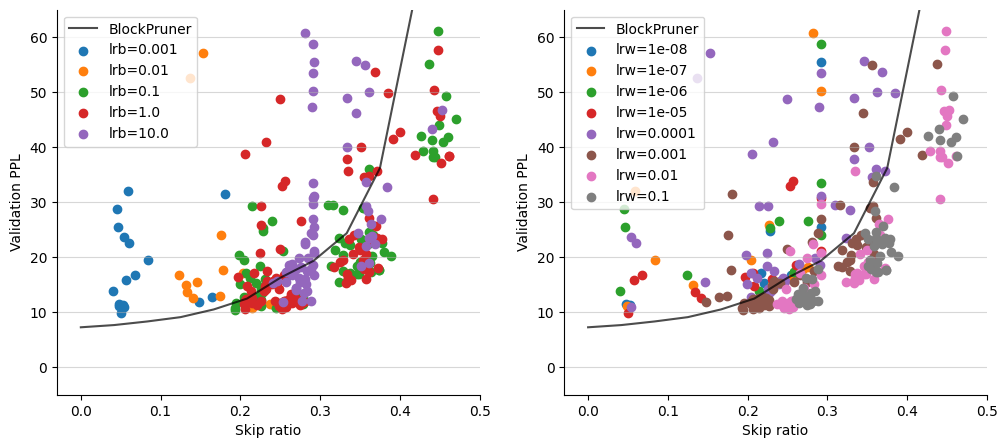

In [79]:
# results_df = gate_results
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

for i, param in enumerate(("lrb", "lrw")):
    ax[i].plot(block_pruner.loc[:13, 'del_ratio'], block_pruner.loc[:13, 'perplexity'], c='black', alpha=0.7, label='BlockPruner')
    for x, group in results_df.groupby(param):
        ax[i].scatter(group["skip_ratio"], group["val_ppl"],
                    label=f"{param}={x}")
    ax[i].set_xlim((-0.03, 0.5))
    ax[i].set_ylim((-5, 65))
    ax[i].grid(axis='y', alpha=0.5)
    ax[i].set_xlabel("Skip ratio")
    ax[i].set_ylabel("Validation PPL")
    ax[i].legend(title=param)
    ax[i].legend(loc="upper left")
    sns.despine()


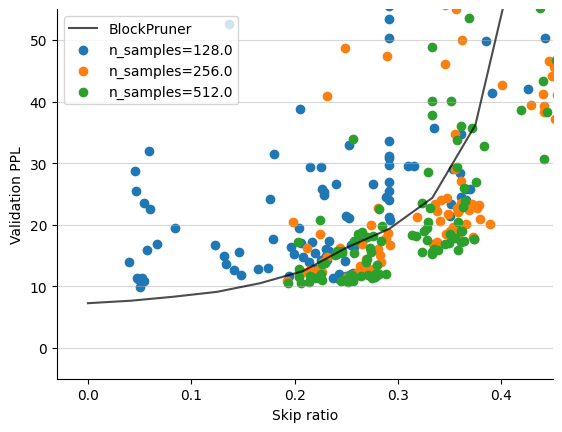

In [80]:
results_df = gate_results
param = "n_samples"
# param = "target_skip"
plt.plot(block_pruner.loc[:13, 'del_ratio'], block_pruner.loc[:13, 'perplexity'], c='black', alpha=0.7, label='BlockPruner')
for x, group in results_df.groupby(param):
    plt.scatter(group["skip_ratio"], group["val_ppl"],
                label=f"{param}={x}")
plt.xlim((-0.03, 0.45))
plt.ylim((-5, 55))
plt.grid(axis='y', alpha=0.5)
plt.xlabel("Skip ratio")
plt.ylabel("Validation PPL")
plt.legend(title=param)
plt.legend(loc="upper left")
sns.despine()
plt.show()

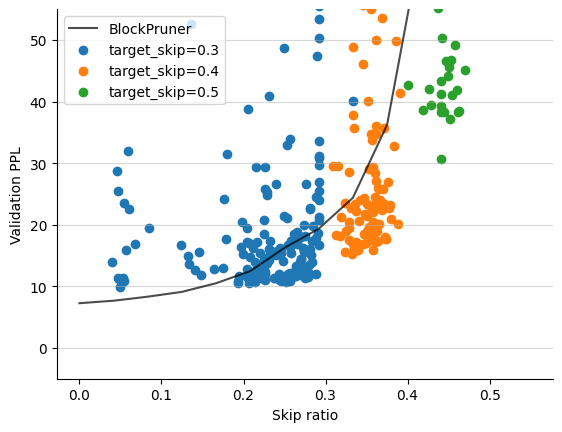

In [81]:
# results_df = gate_results
# param = "n_samples"
param = "target_skip"
plt.plot(block_pruner.loc[:13, 'del_ratio'], block_pruner.loc[:13, 'perplexity'], c='black', alpha=0.7, label='BlockPruner')
for x, group in results_df.groupby(param):
    plt.scatter(group["skip_ratio"], group["val_ppl"],
                label=f"{param}={x}")
# plt.xlim((-0.03, 0.65))
plt.ylim((-5, 55))
plt.grid(axis='y', alpha=0.5)
plt.xlabel("Skip ratio")
plt.ylabel("Validation PPL")
plt.legend(title=param)
plt.legend(loc="upper left")
sns.despine()
plt.show()

## Router Comparison - Selected gates

In [82]:
gate_results_best = gate_results.loc[
    gate_results['lrb'].isin([10, 1, 0.1])
    & gate_results['lrw'].isin([1e-1, 1e-2, 1e-3])
    & (gate_results['val_ppl'] < 60) 
]

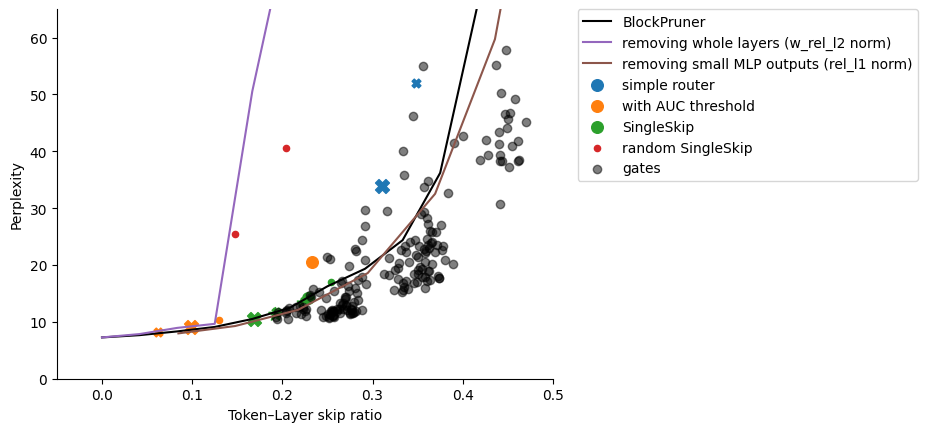

In [83]:
# plt.plot(block_pruner.del_ratio, block_pruner.perplexity)
plt.plot(block_pruner.loc[:13, 'del_ratio'], block_pruner.loc[:13, 'perplexity'], c='black', label='BlockPruner')
plt.plot(wrell2.loc[:13, 'del_ratio'], wrell2.loc[:13, 'perplexity'], c='tab:purple', label='removing whole layers (w_rel_l2 norm)')
plt.plot(small_changes.loc[:, 'ratio_del'], small_changes.loc[:, 'perplexity'], c='tab:brown', label='removing small MLP outputs (rel_l1 norm)')

plt.scatter(results['r'].loc['lr', 'del_ratio'], results['r'].loc['lr', 'perplexity'], marker='o', s=20, c='tab:blue') #, label='LR router')
plt.scatter(results['r'].loc['nn', 'del_ratio'], results['r'].loc['nn', 'perplexity'], marker='o', s=70, c='tab:blue', label='simple router') #, label='NN router')
plt.scatter(results_v2['r'].loc['lr', 'del_ratio'], results_v2['r'].loc['lr', 'perplexity'], marker='X', s=40, c='tab:blue')
plt.scatter(results_v2['r'].loc['nn', 'del_ratio'], results_v2['r'].loc['nn', 'perplexity'], marker='X', s=100, c='tab:blue') #, label='iteratively trained')

###

plt.scatter(results['thr'].loc['lr', 'del_ratio'], results['thr'].loc['lr', 'perplexity'], marker='o', s=20, c='tab:orange')
plt.scatter(results['thr'].loc['nn', 'del_ratio'], results['thr'].loc['nn', 'perplexity'], marker='o', s=70, c='tab:orange', label='with AUC threshold')
plt.scatter(results_v2['thr'].loc['lr', 'del_ratio'], results_v2['thr'].loc['lr', 'perplexity'], marker='X', s=40, c='tab:orange')
plt.scatter(results_v2['thr'].loc['nn', 'del_ratio'], results_v2['thr'].loc['nn', 'perplexity'], marker='X', s=100, c='tab:orange')

###

plt.scatter(results['singleskip'].loc['lr', 'del_ratio'], results['singleskip'].loc['lr', 'perplexity'], marker='o', s=20, c='tab:green')
plt.scatter(results['singleskip'].loc['nn', 'del_ratio'], results['singleskip'].loc['nn', 'perplexity'], marker='o', s=70, c='tab:green', label='SingleSkip')
plt.scatter(results_v2['singleskip'].loc['lr', 'del_ratio'], results_v2['singleskip'].loc['lr', 'perplexity'], marker='X', s=40, c='tab:green')
plt.scatter(results_v2['singleskip'].loc['nn', 'del_ratio'], results_v2['singleskip'].loc['nn', 'perplexity'], marker='X', s=100, c='tab:green')
plt.scatter(results_v3['singleskip'].loc['lr', 'del_ratio'], results_v3['singleskip'].loc['lr', 'perplexity'], marker='*', s=40, c='tab:green')
plt.scatter(results_v3['singleskip'].loc['nn', 'del_ratio'], results_v3['singleskip'].loc['nn', 'perplexity'], marker='*', s=100, c='tab:green')

###

plt.scatter(results['singleskip_rnd'].loc[:, 'del_ratio'], results['singleskip_rnd'].loc[:, 'perplexity'], marker='o', s=20, c='tab:red', label='random SingleSkip')

###

plt.scatter(gate_results_best.skip_ratio, gate_results_best.val_ppl, c='black', alpha=0.5, label='gates')

###

plt.xlim((-0.05, 0.5))
plt.ylim((0, 65))

plt.xlabel('Token–Layer skip ratio')
plt.ylabel('Perplexity')

# plt.legend();
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
sns.despine();

In [84]:
gate_results_best.loc[
    (gate_results_best['skip_ratio'] > 0.3) 
    & (gate_results_best['val_ppl'] < 60)
].sort_values(by='val_ppl')

,n_samples,lrb,lrw,run_i,val_ppl,skip_ratio,init_skip,target_skip
54,512.0,1.0,0.010,1.0,15.315804,0.332835,0.3,0.4
61,512.0,0.1,0.010,0.0,15.537294,0.323583,0.3,0.4
62,512.0,0.1,0.010,1.0,15.649241,0.333262,0.3,0.4
102,512.0,1.0,0.010,1.0,15.842070,0.339157,0.5,0.4
101,512.0,1.0,0.010,0.0,15.962949,0.358022,0.5,0.4
...,...,...,...,...,...,...,...,...
64,256.0,0.1,0.100,0.0,49.231682,0.458099,0.3,0.5
139,128.0,1.0,0.010,0.0,50.324730,0.442413,0.3,0.5
29,256.0,10.0,0.001,1.0,54.991535,0.356018,0.3,0.4
123,512.0,0.1,0.001,0.0,55.200920,0.437129,0.5,0.5


## Final

In [114]:
gate_results = pd.concat([
    pd.read_csv('results/kl_gate_training.csv'),
    pd.read_csv('results/model_stats_results.csv')
])

### Top model selection

In [115]:
gated_model_results = pd.concat([
    gate_results.loc[(gate_results.n_samples==nsamp) & (gate_results.skip_ratio>(skip/100))
        & (gate_results.skip_ratio<((skip+5)/100))
    ].sort_values(by='val_ppl').head(2) 
    for skip in range(15, 47) for nsamp in (128, 256, 512)
], ignore_index=True).drop_duplicates()

In [116]:
gated_model_results.sort_values(by='skip_ratio')

,n_samples,lrb,lrw,run_i,val_ppl,skip_ratio,init_skip,target_skip,run_id
1,128.0,0.001,0.0010,0.0,12.837427,0.164434,0.3,0.3,NaN
2,256.0,0.100,0.0010,0.0,10.787396,0.192891,0.3,0.3,NaN
4,512.0,0.100,0.0010,0.0,10.493101,0.193731,0.5,0.3,NaN
0,128.0,0.100,0.0010,2.0,11.659032,0.195023,0.3,0.3,NaN
3,256.0,0.100,0.0001,0.0,20.393225,0.198532,0.3,0.3,NaN
...,...,...,...,...,...,...,...,...,...
182,256.0,1.000,0.0100,0.0,38.374062,0.461812,0.5,0.5,NaN
183,512.0,1.000,0.1000,0.0,38.455173,0.462199,0.5,0.5,NaN
188,256.0,0.100,0.1000,1.0,45.148918,0.470240,0.5,0.5,NaN
186,128.0,1.000,0.1000,1.0,6672.455566,0.472397,0.3,0.5,NaN


### Visualization

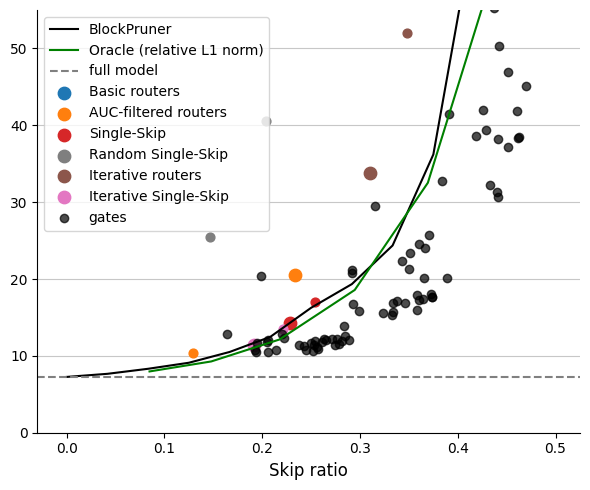

In [117]:
fig, ax = plt.subplots(1, 1, figsize=(6, 5), sharey=False)

ax.plot(block_pruner.loc[:13, 'del_ratio'],
        block_pruner.loc[:13, 'perplexity'],
        c='black', label='BlockPruner')

ax.plot(small_changes.loc[:, 'ratio_del'],
        small_changes.loc[:, 'perplexity'],
        c='g', label='Oracle (relative L1 norm)')

ax.axhline(block_pruner.loc[0, 'perplexity'], c='gray', linestyle='--', label='full model')

ax.scatter(results['r'].loc['lr', 'del_ratio'],
           results['r'].loc['lr', 'perplexity'],
           s=40, c='tab:blue')
ax.scatter(results['r'].loc['nn', 'del_ratio'],
           results['r'].loc['nn', 'perplexity'],
           s=80, c='tab:blue', label='Basic routers')

ax.scatter(results['thr'].loc['lr', 'del_ratio'],
           results['thr'].loc['lr', 'perplexity'],
           s=40, c='tab:orange')
ax.scatter(results['thr'].loc['nn', 'del_ratio'],
           results['thr'].loc['nn', 'perplexity'],
           s=80, c='tab:orange', label='AUC-filtered routers')

ax.scatter(results['singleskip'].loc['lr', 'del_ratio'],
           results['singleskip'].loc['lr', 'perplexity'],
           s=40, c='tab:red')
ax.scatter(results['singleskip'].loc['nn', 'del_ratio'],
           results['singleskip'].loc['nn', 'perplexity'],
           s=80, c='tab:red', label='Single-Skip')

ax.scatter(results['singleskip_rnd'].loc[:, 'del_ratio'],
           results['singleskip_rnd'].loc[:, 'perplexity'],
           s=40, c='tab:gray')
ax.scatter([], [], s=80, c='tab:gray', label='Random Single-Skip')

ax.scatter(results_v2['r'].loc['lr', 'del_ratio'],
           results_v2['r'].loc['lr', 'perplexity'],
           s=40, c='tab:brown')
ax.scatter(results_v2['r'].loc['nn', 'del_ratio'],
           results_v2['r'].loc['nn', 'perplexity'],
           s=80, c='tab:brown', label='Iterative routers')

ax.scatter(results_v3['singleskip'].loc['lr', 'del_ratio'],
           results_v3['singleskip'].loc['lr', 'perplexity'],
           s=40, c='tab:pink')
ax.scatter(results_v3['singleskip'].loc['nn', 'del_ratio'],
           results_v3['singleskip'].loc['nn', 'perplexity'],
           s=80, c='tab:pink', label='Iterative Single-Skip')

### gates
plt.scatter(gated_model_results.skip_ratio, gated_model_results.val_ppl, c='black', alpha=0.7, label='gates')

######

ax.set_xlim((-0.03, 0.525))
ax.set_ylim((0, 55))
ax.set_xlabel('Skip ratio', fontsize=12)
# ax.set_ylabel('Perplexity')

ax.grid(axis='y', linestyle='-', alpha=0.7)
ax.set_axisbelow(True)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)


ax.legend()

plt.tight_layout()

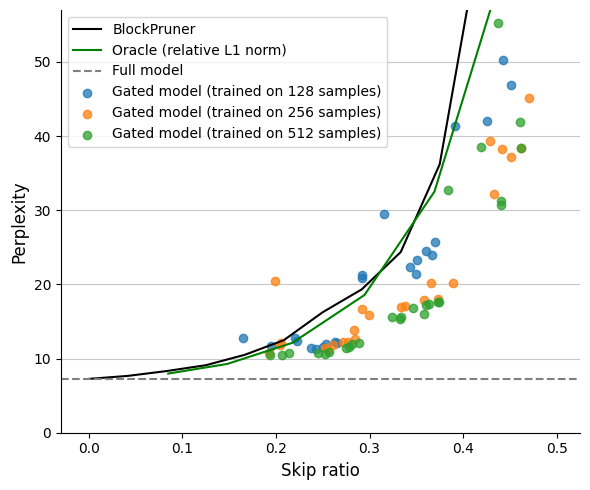

In [118]:
fig, ax = plt.subplots(1, 1, figsize=(6, 5), sharey=False)

ax.plot(block_pruner.loc[:13, 'del_ratio'],
        block_pruner.loc[:13, 'perplexity'],
        c='black', label='BlockPruner')

ax.plot(small_changes.loc[:, 'ratio_del'],
        small_changes.loc[:, 'perplexity'],
        c='g', label='Oracle (relative L1 norm)')

ax.axhline(block_pruner.loc[0, 'perplexity'], c='gray', linestyle='--', label='Full model')


### gates
param = "n_samples"
for x, group in gated_model_results.groupby(param):
    ax.scatter(group["skip_ratio"], group["val_ppl"],
               # label=f"{param}={x}", alpha=0.75)
               label=f"Gated model (trained on {int(x)} samples)", alpha=0.75)
######

ax.set_xlim((-0.03, 0.525))
ax.set_ylim((0, 57))
ax.set_xlabel('Skip ratio', fontsize=12)
ax.set_ylabel('Perplexity', fontsize=12)

ax.grid(axis='y', linestyle='-', alpha=0.7)
ax.set_axisbelow(True)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)


ax.legend()

plt.tight_layout()

### Top Model Table

In [119]:
gated_model_results = pd.concat([
    gate_results.loc[
        (gate_results.n_samples == nsamp) &
        (gate_results.skip_ratio > (skip / 100)) &
        (gate_results.skip_ratio < ((skip + 3) / 100))
    ]
    .sort_values("val_ppl")
    .head(1)
    .assign(skip=skip)   # store row label
    for skip in range(20, 46, 5)
    for nsamp in (128, 256, 512)
], ignore_index=True).drop_duplicates()

gated_model_results = gated_model_results.set_index("skip")

In [120]:
dfs = []

for n in [128, 256, 512]:
    df = (
        gated_model_results
        .query("n_samples == @n")[['val_ppl', 'skip_ratio']]
    )
    # add top-level header
    df.columns = pd.MultiIndex.from_product([[n], df.columns])
    dfs.append(df)

pd.concat(dfs, axis=1).round(2)

128                256                512           
     val_ppl skip_ratio val_ppl skip_ratio val_ppl skip_ratio
skip                                                         
20     12.35       0.22   11.84       0.20   10.52       0.21
25     11.61       0.25   11.14       0.26   10.66       0.25
30     29.50       0.32   21.31       0.32   15.54       0.32
35     21.34       0.35   17.86       0.36   15.96       0.36
40     41.99       0.43   39.39       0.43   38.55       0.42
45     46.90       0.45   37.16       0.45   38.46       0.46